In [90]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder,PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error,mean_absolute_error,r2_score

In [91]:
df = pd.read_csv("House_Price_dataset - House_Price_dataset.csv")
df

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4.0,2.0,3.0,yes,no,no,no,yes,2.0,yes,furnished
1,12250000,8960,4.0,4.0,4.0,yes,no,no,no,yes,3.0,no,furnished
2,12250000,9960,3.0,2.0,2.0,yes,no,yes,no,no,2.0,yes,semi-furnished
3,12215000,7500,4.0,2.0,2.0,yes,no,yes,no,yes,3.0,yes,furnished
4,11410000,7420,4.0,1.0,2.0,yes,yes,yes,no,yes,2.0,no,furnished
...,...,...,...,...,...,...,...,...,...,...,...,...,...
540,1820000,3000,2.0,1.0,1.0,yes,no,yes,no,no,2.0,no,unfurnished
541,1767150,2400,3.0,1.0,1.0,no,no,no,no,no,0.0,no,semi-furnished
542,1750000,3620,2.0,1.0,1.0,yes,no,no,no,no,0.0,no,unfurnished
543,1750000,2910,3.0,1.0,1.0,no,no,no,no,no,0.0,no,furnished


In [92]:
df['bedrooms'] = df['bedrooms'].fillna(df['bedrooms'].median())
df['bathrooms'] = df['bathrooms'].fillna(df['bathrooms'].median())
df['stories'] = df['stories'].fillna(df['stories'].median())
df['parking'] = df['parking'].fillna(df['parking'].median())

In [93]:
le = LabelEncoder()
df["mainroad"] = le.fit_transform(df["mainroad"])
df["guestroom"] = le.fit_transform(df["guestroom"])
df["basement"] = le.fit_transform(df["basement"])
df["hotwaterheating"] = le.fit_transform(df["hotwaterheating"])
df["airconditioning"] = le.fit_transform(df["airconditioning"])
df["prefarea"] = le.fit_transform(df["prefarea"])
df["furnishingstatus"] = le.fit_transform(df["furnishingstatus"])

In [94]:
X = df[['area']]
y = df['price']
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=42,test_size = 0.2)

In [95]:
reg = LinearRegression()
reg.fit(X_train,y_train)
print("Coefficients:", reg.coef_)
print("Intercept:", reg.intercept_)      

Coefficients: [425.72984194]
Intercept: 2512254.2639593435


In [96]:
y_pred = reg.predict(X_test)

In [97]:
y_pred_1 = reg.predict(X_train)

In [98]:
mse = mean_squared_error(y_test, y_pred)
mae = mean_absolute_error(y_test,y_pred)
r_square = r2_score(y_test,y_pred)
print('Mean Squared error on training only with area:',mse)
print('Mean absolute error on training only with area:',mae)
print('r2 on training only with area:',r_square)

Mean Squared error on training only with area: 3675286604768.185
Mean absolute error on training only with area: 1474748.1337969352
r2 on training only with area: 0.27287851871974644


In [99]:
import matplotlib.pyplot as plt

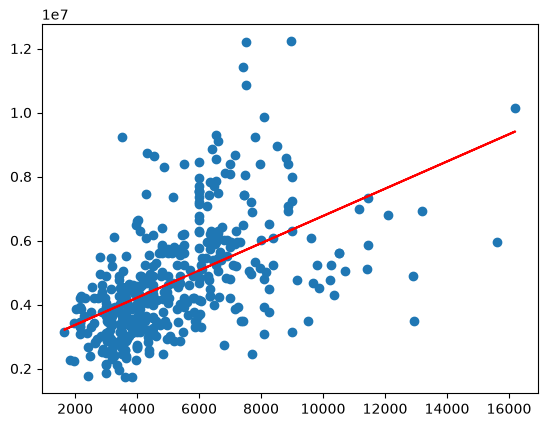

In [100]:
plt.scatter(X_train,y_train)
plt.plot(X_train,y_pred_1,c="Red")

In [101]:
X = df.drop('price',axis=1)
y = df['price']
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=42,test_size = 0.2)

In [102]:
X_train

,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
46,6000,3.0,2.0,4.0,1,0,0,0,1,1.0,0,0
93,7200,3.0,2.0,1.0,1,0,1,0,1,3.0,0,1
335,3816,2.0,1.0,1.0,1,0,1,0,1,2.0,0,0
412,2610,3.0,1.0,2.0,1,0,1,0,0,0.0,1,2
471,3750,3.0,1.0,2.0,1,0,0,0,0,0.0,0,2
...,...,...,...,...,...,...,...,...,...,...,...,...
71,6000,4.0,2.0,4.0,1,0,0,0,1,0.0,0,2
106,5450,4.0,2.0,1.0,1,0,1,0,1,0.0,1,1
270,4500,3.0,2.0,3.0,1,0,0,1,0,1.0,0,0
435,4040,2.0,1.0,1.0,1,0,0,0,0,0.0,0,2


In [103]:
X_train.dtypes

area                  int64
bedrooms            float64
bathrooms           float64
stories             float64
mainroad              int64
guestroom             int64
basement              int64
hotwaterheating       int64
airconditioning       int64
parking             float64
prefarea              int64
furnishingstatus      int64
dtype: object

In [104]:
reg = LinearRegression()
reg.fit(X_train,y_train)
print("Coefficients:", reg.coef_)
print("Intercept:", reg.intercept_)      

Coefficients: [ 2.38661524e+02  9.74306538e+04  1.05365483e+06  4.02429843e+05
  3.76507984e+05  2.32037535e+05  3.84678718e+05  6.87087166e+05
  7.96416107e+05  2.15766903e+05  6.20512488e+05 -2.20617486e+05]
Intercept: 303345.3356136447


In [105]:
y_pred = reg.predict(X_test)

In [106]:
mse = mean_squared_error(y_test, y_pred)
mae = mean_absolute_error(y_test,y_pred)
r_square = r2_score(y_test,y_pred)
print('Mean Squared error on training only with area:',mse)
print('Mean absolute error on training only with area:',mae)
print('r2 on training only with area:',r_square)

Mean Squared error on training only with area: 1762261595678.3108
Mean absolute error on training only with area: 974800.4763575838
r2 on training only with area: 0.6513528332210875


In [107]:
poly = PolynomialFeatures()
X_train_poly = poly.fit_transform(X_train)
X_test_poly = poly.transform(X_test)

In [108]:
X_train_poly

array([[1.000e+00, 6.000e+03, 3.000e+00, ..., 0.000e+00, 0.000e+00,
        0.000e+00],
       [1.000e+00, 7.200e+03, 3.000e+00, ..., 0.000e+00, 0.000e+00,
        1.000e+00],
       [1.000e+00, 3.816e+03, 2.000e+00, ..., 0.000e+00, 0.000e+00,
        0.000e+00],
       ...,
       [1.000e+00, 4.500e+03, 3.000e+00, ..., 0.000e+00, 0.000e+00,
        0.000e+00],
       [1.000e+00, 4.040e+03, 2.000e+00, ..., 0.000e+00, 0.000e+00,
        4.000e+00],
       [1.000e+00, 5.500e+03, 3.000e+00, ..., 0.000e+00, 0.000e+00,
        1.000e+00]], shape=(436, 91))

In [109]:
poly_model = LinearRegression()
poly_model.fit(X_train_poly,y_train)
print("Coefficients:", poly_model.coef_)
print("Intercept:", poly_model.intercept_)

Coefficients: [ 7.24881604e-12 -2.14646226e+01  1.31808990e-02  2.79224849e-02
  1.84522376e-02  3.17499228e-02 -6.45311177e-04  1.38040429e-02
  2.51050378e-02  2.52036155e-02  8.86041126e-03  2.12456889e-02
 -7.45195960e-03 -2.41847965e-02  3.23716815e+01  1.70676568e+02
  5.31038940e+01  1.17791030e+02 -6.83736598e+00  8.22533413e+01
  1.52786591e+02  1.46836475e+02  2.32545955e+01  9.33494795e+01
 -4.10794473e+01  7.99799720e-02  1.14285507e-01  7.04074125e-02
  1.04178323e-01  7.16986530e-04  4.80699550e-02  7.56378096e-02
  7.92431341e-02  4.06946130e-02  6.83549562e-02  3.97991623e-04
  9.34902948e-02  7.96355600e-02  6.35275401e-02  3.60724968e-03
  2.67450923e-02  3.55073176e-02  4.27476601e-02  3.94309528e-02
  3.51206020e-02  2.26612386e-02  7.17929183e-02  6.58230191e-02
  1.23365978e-04  2.28847967e-02  4.52947955e-02  4.74626093e-02
  2.97747491e-02  4.23904674e-02  3.12297269e-03  3.17499228e-02
  1.57450163e-03  1.84143473e-02  2.36880781e-02  2.91295984e-02
  1.8275238

In [110]:
y_pred_poly = poly_model.predict(X_test_poly)

In [112]:
mse = mean_squared_error(y_test, y_pred_poly)
mae = mean_absolute_error(y_test,y_pred_poly)
r_square = r2_score(y_test,y_pred_poly)
print('Mean Squared error on polynomial regression:',mse)
print('Mean absolute error on polynomial regression:',mae)
print('r2 on polynomial regression:',r_square)

Mean Squared error on polynomial regression: 1761881461715.7175
Mean absolute error on polynomial regression: 1008480.8656210513
r2 on polynomial regression: 0.6514280392117189


In [113]:
area = int(input("Enter area: "))
bedrooms = float(input("Enter number of bedrooms: "))
bathrooms = float(input("Enter number of bathrooms: "))
stories = float(input("Enter number of stories: "))
mainroad = int(input("Near Main road?\n0. Yes\n1. No: "))
guestroom = int(input("Guest rooms?\n0. Yes\n1. No: "))
basement = int(input("Basement?:\n0. Yes\n1. No: "))
hotwaterheating = int(input("Hot water heating?\n0. Yes\n1. No: "))
airconditioning = int(input("Air-conditioning?\n0. Yes\n1. No: "))
parking = float(input("Enter number of parkings: "))
prefarea = int(input("Preferred area?\n0. Yes\n1. No: "))
furnishingstatus = int(input("Furnishing Status:\n0. Furnished\n1. Semi-furnished\n2. Unfurnished: "))

df = pd.DataFrame({
    'area': [area],
    'bedrooms': [bedrooms],
    'bathrooms': [bathrooms],
    'stories': [stories],
    'mainroad': [mainroad],
    'guestroom': [guestroom],
    'basement': [basement],
    'hotwaterheating': [hotwaterheating],
    'airconditioning': [airconditioning],
    'parking': [parking],
    'prefarea': [prefarea],
    'furnishingstatus': [furnishingstatus]
})

df_poly = poly.transform(df)
user_pred_poly = poly_model.predict(df_poly)

print("Predicted price: ", user_pred_poly[0])

Enter area:  7500
Enter number of bedrooms:  3
Enter number of bathrooms:  2
Enter number of stories:  1
Near Main road?
0. Yes
1. No:  0
Guest rooms?
0. Yes
1. No:  0
Basement?:
0. Yes
1. No:  1
Hot water heating?
0. Yes
1. No:  0
Air-conditioning?
0. Yes
1. No:  0
Enter number of parkings:  2
Preferred area?
0. Yes
1. No:  1
Furnishing Status:
0. Furnished
1. Semi-furnished
2. Unfurnished:  0


Predicted price:  [6257112.58615333]
